In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the .arff file
data, meta = arff.loadarff('D:/Major Project/phishing-detection-ml-system/data/Training Dataset.arff')

# Convert to pandas DataFrame
df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (11055, 31)


In [3]:
# Show first 5 rows
print("First 5 rows:")
df.head()

First 5 rows:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,b'-1',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',b'1',b'-1',b'-1'
1,b'1',b'1',b'1',b'1',b'1',b'-1',b'0',b'1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'-1'
2,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'1',b'-1',b'1',b'-1',b'1',b'0',b'-1',b'-1'
3,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'1',b'1',...,b'1',b'1',b'-1',b'-1',b'1',b'-1',b'1',b'-1',b'1',b'-1'
4,b'1',b'0',b'-1',b'1',b'1',b'-1',b'1',b'1',b'-1',b'1',...,b'-1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'1'


In [4]:
# Show all column names
print("Column names:")
print(df.columns.tolist())

Column names:
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']


In [5]:
# Check data types and missing values
print("Dataset Info:")
print(df.info())

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   having_IP_Address            11055 non-null  object
 1   URL_Length                   11055 non-null  object
 2   Shortining_Service           11055 non-null  object
 3   having_At_Symbol             11055 non-null  object
 4   double_slash_redirecting     11055 non-null  object
 5   Prefix_Suffix                11055 non-null  object
 6   having_Sub_Domain            11055 non-null  object
 7   SSLfinal_State               11055 non-null  object
 8   Domain_registeration_length  11055 non-null  object
 9   Favicon                      11055 non-null  object
 10  port                         11055 non-null  object
 11  HTTPS_token                  11055 non-null  object
 12  Request_URL                  11055 non-null  object
 13  URL_of_Anchor               

In [6]:
# Convert byte strings to integers
df = df.map(lambda x: int(x.decode('utf-8')))

print("Data types after conversion:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows after conversion:")
df.head()

Data types after conversion:
int64    31
Name: count, dtype: int64

First 5 rows after conversion:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [7]:
# Check how many phishing vs legitimate URLs we have
print("Target column distribution:")
print(df['Result'].value_counts())
print("\nPercentage:")
print(df['Result'].value_counts(normalize=True) * 100)

Target column distribution:
Result
 1    6157
-1    4898
Name: count, dtype: int64

Percentage:
Result
 1    55.694256
-1    44.305744
Name: proportion, dtype: float64


In [8]:
# Check for duplicates
print("Number of duplicate rows:", df.duplicated().sum())

# Remove duplicates if any
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 5206
Shape after removing duplicates: (5849, 31)


In [9]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values per column:
having_IP_Address              0
URL_Length                     0
Shortining_Service             0
having_At_Symbol               0
double_slash_redirecting       0
Prefix_Suffix                  0
having_Sub_Domain              0
SSLfinal_State                 0
Domain_registeration_length    0
Favicon                        0
port                           0
HTTPS_token                    0
Request_URL                    0
URL_of_Anchor                  0
Links_in_tags                  0
SFH                            0
Submitting_to_email            0
Abnormal_URL                   0
Redirect                       0
on_mouseover                   0
RightClick                     0
popUpWidnow                    0
Iframe                         0
age_of_domain                  0
DNSRecord                      0
web_traffic                    0
Page_Rank                      0
Google_Index                   0
Links_pointing_to_page         0
Statistical_repo

In [10]:
# Check unique values in each column
print("Unique values in each column:")
for col in df.columns:
    unique_vals = df[col].unique()
    print(f"{col}: {sorted(unique_vals)}")

Unique values in each column:
having_IP_Address: [np.int64(-1), np.int64(1)]
URL_Length: [np.int64(-1), np.int64(0), np.int64(1)]
Shortining_Service: [np.int64(-1), np.int64(1)]
having_At_Symbol: [np.int64(-1), np.int64(1)]
double_slash_redirecting: [np.int64(-1), np.int64(1)]
Prefix_Suffix: [np.int64(-1), np.int64(1)]
having_Sub_Domain: [np.int64(-1), np.int64(0), np.int64(1)]
SSLfinal_State: [np.int64(-1), np.int64(0), np.int64(1)]
Domain_registeration_length: [np.int64(-1), np.int64(1)]
Favicon: [np.int64(-1), np.int64(1)]
port: [np.int64(-1), np.int64(1)]
HTTPS_token: [np.int64(-1), np.int64(1)]
Request_URL: [np.int64(-1), np.int64(1)]
URL_of_Anchor: [np.int64(-1), np.int64(0), np.int64(1)]
Links_in_tags: [np.int64(-1), np.int64(0), np.int64(1)]
SFH: [np.int64(-1), np.int64(0), np.int64(1)]
Submitting_to_email: [np.int64(-1), np.int64(1)]
Abnormal_URL: [np.int64(-1), np.int64(1)]
Redirect: [np.int64(0), np.int64(1)]
on_mouseover: [np.int64(-1), np.int64(1)]
RightClick: [np.int64(-1

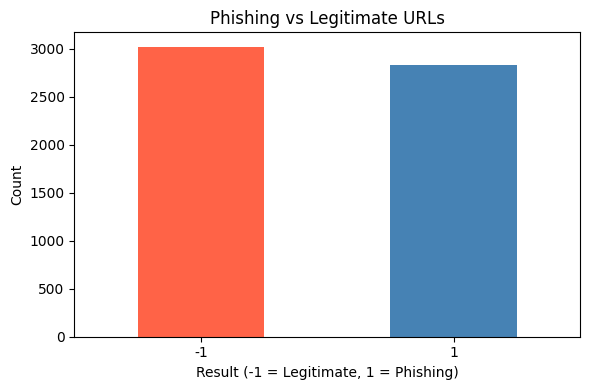

Cleaned dataset distribution:
Result
-1    3019
 1    2830
Name: count, dtype: int64


In [11]:
# Visualize phishing vs legitimate distribution
plt.figure(figsize=(6, 4))
df['Result'].value_counts().plot(kind='bar', color=['tomato', 'steelblue'])
plt.title('Phishing vs Legitimate URLs')
plt.xlabel('Result (-1 = Legitimate, 1 = Phishing)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Cleaned dataset distribution:")
print(df['Result'].value_counts())

In [12]:
# Save cleaned dataset as CSV
df.to_csv('D:/Major Project/phishing-detection-ml-system/data/phishing_urls_cleaned.csv', index=False)
print("Cleaned dataset saved successfully!")
print("Final shape:", df.shape)

Cleaned dataset saved successfully!
Final shape: (5849, 31)
